In [1]:
import numpy as np
from numpy.polynomial import chebyshev as cheb
from scipy import optimize
import matplotlib.pyplot as plt
from tqdm import tqdm
import matplotlib as mpl
import matplotlib.cm as cm
from scipy.ndimage import zoom, gaussian_filter
import uuid
from numba import njit, prange
from numba_progress import ProgressBar
from scipy.stats import binned_statistic

# Force Modell

In [2]:
Lp = 1.5 # um Persistence length
kbT = 1

In [3]:
def x_entropic_force(Fe):
    return 1 / np.tanh(2 * Lp * Fe / kbT) - kbT / (2 * Lp * Fe)

def dx_entropic_force(Fe):
    return 1 / (2 * Lp * Fe**2 / kbT) - 2 * Lp / kbT / np.sinh(2 * Lp * Fe / kbT)**2

In [4]:
def create_F(k, sample_density_x=1e-3, n_iter_equalize=5, x_max_full=5, cheb_subsampling = 16):
    
    ''' Creates a force curve for a given w.
        We return a chebychev polynomial that
        approximates the entire curve.

        From the experimental force rate w:
        k = w / v
    '''

    # Find F*, the transition from entropic to hookean force.
    res = optimize.root_scalar(lambda fe: dx_entropic_force(fe) - 1/k, bracket=(1e-12, 30))
    F_star = res.root

    # Determine the x range for forces to occur between 0 and F*
    x_min = x_entropic_force(sample_density_x)
    x_max = x_entropic_force(F_star)

    # Construct an even x grid of forces using the derivative of x
    n_x = max(int((x_max - x_min) / sample_density_x), 2)
    F  = np.linspace(1e-12, F_star, n_x)
    for _ in range(n_iter_equalize):
        cdx = np.cumsum(1/dx_entropic_force(F))
        cdx = cdx - cdx[0]
        cdx = cdx / cdx[-1]
        F = cdx * (F_star) + sample_density_x
    x = x_entropic_force(F)

    # The Hookean tail
    hook_tail_length = x_max_full - x_max
    xh = np.linspace(sample_density_x, hook_tail_length, int((hook_tail_length - sample_density_x) / sample_density_x))
    Fh = k * xh + F[-1]

    x = np.concatenate(([0], x, xh + x[-1]))
    F = np.concatenate(([0], F, Fh))

    C = cheb.Chebyshev.fit(x, F, len(x)//cheb_subsampling)
    
    return C, x, F

# Simulate Trajectories

def sim(C, ru0, xu, v=0.2, dt=1e-2):
    t = 0
    ft = [C(t*v)]
    while True:
        assert v*t < C.domain.max(), "Force left Chebychev domain"
        pu = np.clip(dt * ru0 * np.exp(C(v*t)*xu), 0, 1)
        if pu > np.random.rand(1):
            break
        ft.append(C(v*t))
        t += dt

    return np.array(ft)

Text(0, 0.5, 'F')

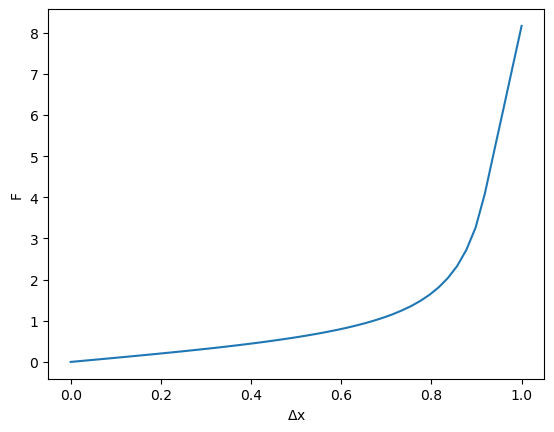

In [5]:
C, _, _ = create_F(50)
x = np.linspace(0, 1)
F = C(x)
plt.plot(x,F)
plt.xlabel("$\Delta$x")
plt.ylabel("F")

# Simulate Trajectories

In [6]:
class EndOfCache(Exception):
    "End of cache reached, some bonds did not break"
    pass

class ExceededLUT(Exception):
    "End of force LUT reached"
    pass

@njit(parallel=True)
def nb_trajectories(ruxu, v, lut_x, lut_F, dt, cache_length=10000):
    N = ruxu.shape[0]

    lut_size = lut_x.shape[0]
    lut_maxx = lut_x[-1]

    force = np.full((cache_length, N), np.nan) # The force at each time step
    bound = np.full(N, True) # Keeping track if the bond is active
    event = np.zeros(N) # Index of when the unbinding even occurs
    
    t = 0 # Time index
    force[t, :] = 0

    bonds_left = True

    while bonds_left == True:

        t+=1
        
        for sample in prange(N):
            
            ru = ruxu[sample, 0]
            xu = ruxu[sample, 1]
            
            if bound[sample]:
                x = v[sample] * t * dt
                if x >= lut_maxx:
                    x = lut_maxx
                    #raise ExceededLUT
                idx = lut_size * x / lut_maxx
                f = lut_F[int(idx)]
                force[t, sample] = f
                
                pu = min(dt * ru * np.exp(f*xu), 1)
                a  = np.random.rand()

                if pu > a:
                    bound[sample] = False
                    event[sample] = t

        bonds_left = np.any(bound)
        if t == cache_length:
            raise EndOfCache
            break

    end_of_sim = int(np.max(event))
    force = force[:end_of_sim+1, :]

    return force, event


In [7]:
@njit(parallel=True, nogil=True)
def nb_likelihood(logprior, ruxu, T, event, dt, pbar=None, kl_per_T=False):

    n_samples = logprior.shape[0]
    n_trajectories = event.shape[0]
    logposterior = logprior.copy()

    if kl_per_T:
        klT = np.zeros(n_trajectories)

    for s in prange(n_samples):
        ru = ruxu[s, 0]
        xu = ruxu[s, 1]
        for t in range(n_trajectories):
            for i in range(int(event[t])):
                p = 1 - dt * ru * np.exp(T[i, t] * xu)
                
                if p > 1:
                    p = 1
                if p < 0:
                    p = 0
                    
                if i + 1 == event[t]: # in case of unbinding
                    p = 1 - p

                logp = np.log(p + 1e-10)
                logposterior[s] += logp
                if kl_per_T:
                    klT[t] += logp
        pbar.update(1)

    return logposterior, klT
                

OMP: Info #276: omp_set_nested routine deprecated, please use omp_set_max_active_levels instead.


  0%|                                                                | 0/10000 [00:00<?, ?it/s]

Text(0, 0.5, 'xu')

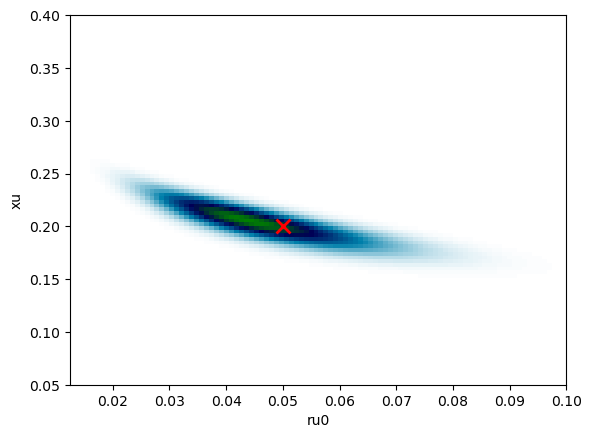

In [8]:
ru0_GT = 0.05
xu_GT  = 0.2
dt = 1e-2

x = np.linspace(0, 5, 10000)
F = C(x)
force_lut = (x, F)

N_trajectories = 50
ruxu_data = np.array([ru0_GT, xu_GT])[np.newaxis,:].repeat(N_trajectories, axis=0)
v = np.random.uniform(0.01, 0.4, size=N_trajectories)

T, event = nb_trajectories(ruxu_data, v, x, F, dt=dt)
#plt.plot(T[:, :10])
#for e in event[:10]:
#    plt.axvline(e, alpha=0.1, color='k')

resolution = 100
xu_max = xu_GT * 2
ru_max = ru0_GT * 2
xu_min = xu_GT / 4
ru_min = ru0_GT / 4

ru = np.linspace(ru_min, ru_max, resolution)
xu = np.linspace(xu_min, xu_max, resolution)

ruxu = np.stack(np.meshgrid(ru, xu)).reshape((-1, resolution**2)).T

logprior = np.zeros(resolution**2)
with ProgressBar(total=resolution**2) as pbar:
    logpost, klT = nb_likelihood(logprior, ruxu, T, event, dt=dt, pbar=pbar)

N_trajectories_effective = N_trajectories
factor = 1
logpost_ = logpost.copy().reshape((resolution, -1))
logpost_ -= np.nanmax(logpost_)
plt.imshow(np.exp(logpost_ / factor), origin='lower', cmap='ocean_r', extent=(ru_min, ru_max, xu_min, xu_max), aspect='auto')
plt.plot([ru0_GT],[xu_GT], 'rx', markersize=10, markeredgewidth=2)
plt.xlabel("ru0")
plt.ylabel("xu")

50 Measurements


Text(0, 0.5, 'Force')

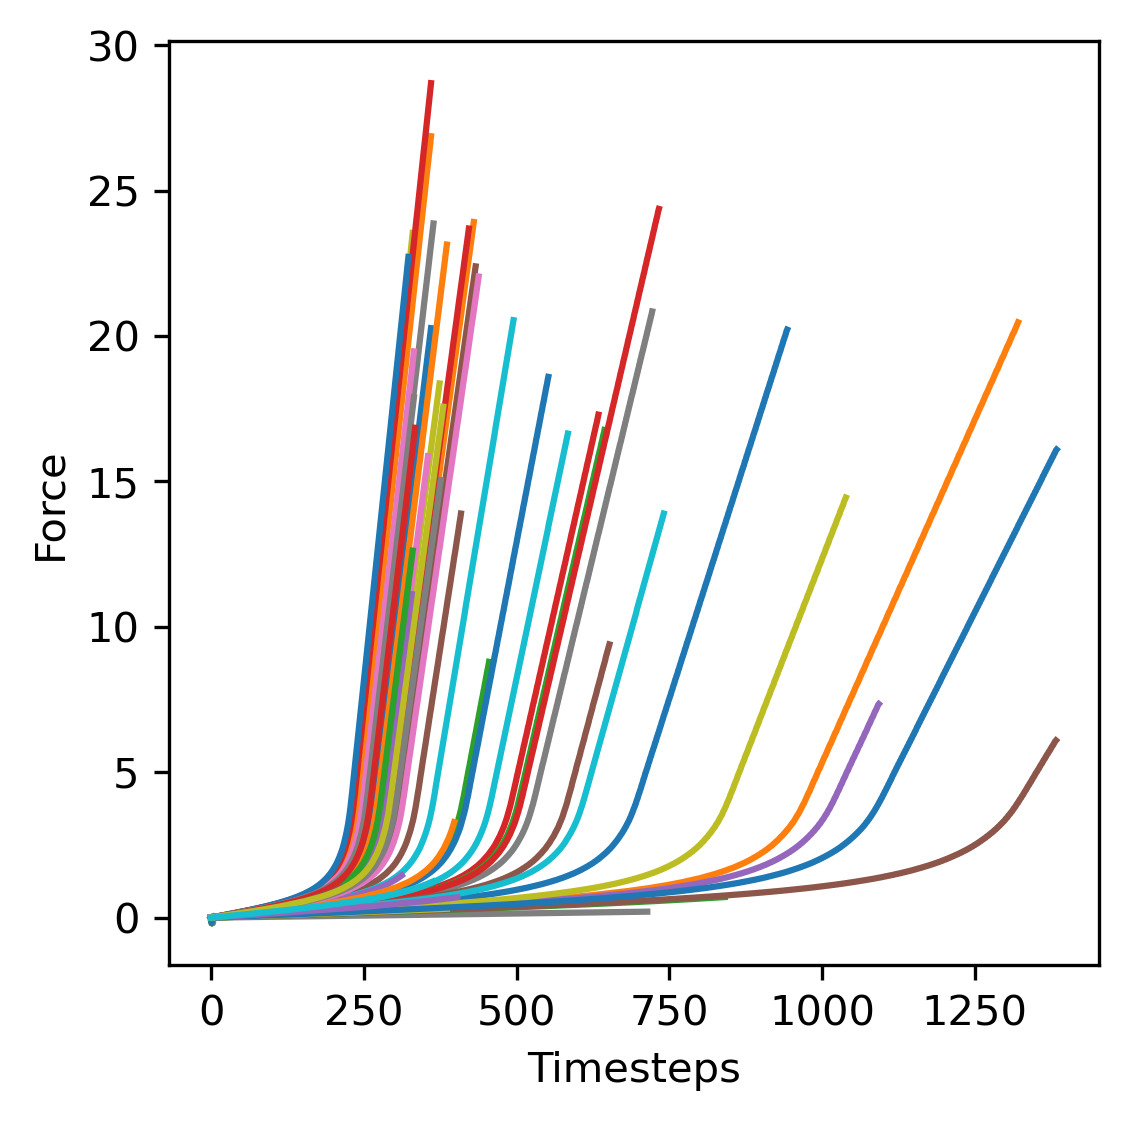

In [9]:
plt.figure(figsize=(4,4), dpi=300)
for i, f in enumerate(T.T):
    plt.plot(f)
print(len(T.T), "Measurements")
plt.xlabel("Timesteps")
plt.ylabel("Force")

# BOED

In [10]:
def KLdivergence(P, Q):
    P = P.copy() + 1e-14
    Q = Q.copy() + 1e-14
    return np.sum(P * (np.log(P) - np.log(Q)))

In [11]:
def sample_from_logp(logp, data, n_samples):
    n_datapoints = logp.shape[0]
    idx_datapoints = np.arange(n_datapoints)
    p = np.exp(logp)
    p = p / p.sum()
    idx = np.random.choice(idx_datapoints, size=n_samples, p=p, replace=True)
    return data[idx, :]

  0%|                                                                | 0/10000 [00:00<?, ?it/s]

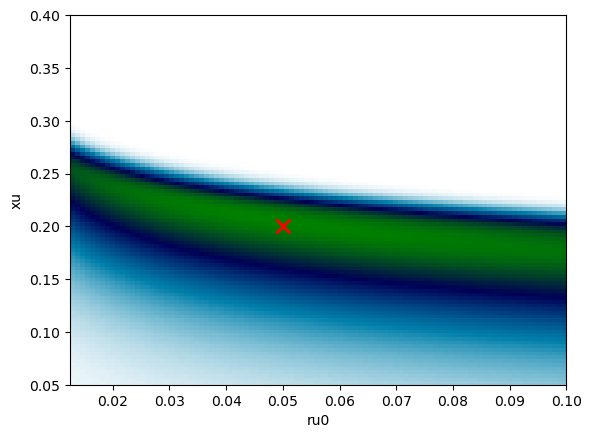

Text(0, 0.5, 'Expected relative entropy change')

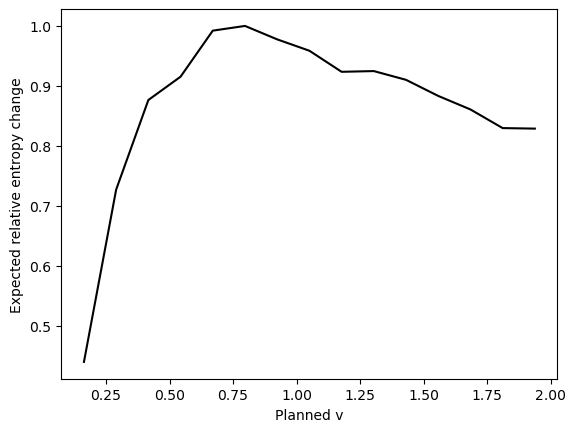

In [13]:
logprior = np.zeros(resolution**2)
N_trajectories = 100000
ruxu_data = np.array([ru0_GT, xu_GT])[np.newaxis,:].repeat(N_trajectories, axis=0)
#ruxu_data = sample_from_logp(logprior, ruxu, N_trajectories)
v2 = np.random.uniform(0.1, 2, size=N_trajectories)
T2, event2 = nb_trajectories(ruxu_data, v2, x, F, dt=dt)
#plt.plot(T2[:, :10])
#for e in event2[:10]:
#    plt.axvline(e, alpha=0.1, color='k')
#plt.show()
#logprior = logpost

ruxu_data = np.stack(np.meshgrid(ru, xu)).reshape((-1, resolution**2)).T

with ProgressBar(total=resolution**2) as pbar:
    logpost2, klT = nb_likelihood(logprior, ruxu_data, T2, event2, dt=dt, pbar=pbar, kl_per_T=True)

#print(klT)
logpost_ = logpost2.copy().reshape((resolution, -1))
logpost_ -= np.nanmax(logpost_)
plt.imshow(np.exp(logpost_ / N_trajectories), origin='lower', cmap='ocean_r', extent=(ru_min, ru_max, xu_min, xu_max), aspect='auto')
plt.plot([ru0_GT],[xu_GT], 'rx', markersize=10, markeredgewidth=2)
plt.xlabel("ru0")
plt.ylabel("xu")
plt.show()

stat = binned_statistic(v2, klT, bins=15)
v_test = (stat.bin_edges[:-1] + stat.bin_edges[1:])/2
kl_test = stat.statistic / stat.statistic.min()
plt.plot(v_test, kl_test, 'k')
#plt.plot(v2, klT)
plt.xlabel("Planned v")
plt.ylabel("Expected relative entropy change")